In [26]:
import numpy as np
import pandas as pd
import glob
import os
import json
from quantile_forest import RandomForestQuantileRegressor
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split

tmax_train = pd.read_parquet(r"..\Data_Temp\Processed\Monthly_downscaling\final_tmax_train_df.parquet")
tmax_test = pd.read_parquet(r"..\Data_Temp\Processed\Monthly_downscaling\final_tmax_test_df.parquet")
model_path = fr"..\Data_Temp\Processed\Monthly_downscaling\Saved_regressors"


def get_model_features(t_var:str):
    metadata_file = glob.glob(os.path.join(model_path, f"{t_var}_*_feature_metadata.json"))[0]
    with open(metadata_file, 'r') as f:
            metadata = json.load(f)
    predictor_features = metadata['input_features']
    model_type = metadata['model_type']
    return model_type, predictor_features

model_type_tmax, predictor_features_tmax = get_model_features("tmax")

tmax_train = tmax_train.dropna(subset=['IS_tmax_average'])
tmax_test = tmax_test.dropna(subset=['IS_tmax_average'])

X_train = tmax_train[predictor_features_tmax]
y_train = tmax_train['IS_tmax_average']

X_test = tmax_test[predictor_features_tmax]
y_test = tmax_test['IS_tmax_average']

X_train_medians = X_train.median()
X_train = X_train.fillna(X_train_medians)
X_test = X_test.fillna(X_train_medians)
qrf = RandomForestQuantileRegressor(n_estimators=100, random_state=22)
qrf.fit(X_train, y_train)

# 3. Generate 100 random quantiles for stochastic ensemble simulation
# To get 100 stochastic draws for each test sample, we sample 100 random percentiles
np.random.seed(42)
n_samples_to_draw = 100
random_quantiles = np.random.uniform(0.0, 1.0, size=100)

# 4. Predict the ensemble values
# Result shape will be (num_test_samples, 100)
stochastic_ensemble = np.column_stack([
    qrf.predict(X_test, quantiles=q) for q in random_quantiles
])
# 5. Review the shape and a sample output
median_predictions = qrf.predict(X_test, quantiles=0.5)
print(f"Median predictions shape: {median_predictions.shape}")
print(f"Median prediction for the first test point: {median_predictions[100]}")
print(f"Ensemble matrix shape: {stochastic_ensemble.shape}")
print(f"100 stochastic predictions for the first test point:\n{stochastic_ensemble[100]}")
print(f"median of stochastic ensemble", np.median(stochastic_ensemble[100]))

Median predictions shape: (1322,)
Median prediction for the first test point: 32.37096774193548
Ensemble matrix shape: (1322, 100)
100 stochastic predictions for the first test point:
[31.82580645 35.13       33.06451613 32.87741935 30.67419355 30.67419355
 29.62749637 33.58333333 32.87741935 32.96492726 29.41935484 35.13
 33.57666667 30.80645161 30.73870968 30.73870968 31.38455896 32.40310216
 32.07419355 31.35736213 32.87741935 30.62270091 31.37134726 31.81183101
 32.15666667 33.37096774 30.74737731 32.37096774 32.86156965 29.41935484
 32.87741935 30.67419355 29.72232883 35.12838466 35.13       33.55864746
 31.38493468 29.83912827 32.92145686 32.10573112 30.14929392 32.37096774
 29.41935484 33.73966244 31.11612903 32.87741935 31.39211212 32.38741651
 32.51288255 30.73870968 35.13       33.35322948 35.10350413 33.70764767
 32.87741935 33.78064516 29.77934596 30.74325181 29.41935484 31.44042241
 31.82580645 31.11612903 33.57666667 31.71200049 31.20786476 32.4960368
 30.66105636 33.4772

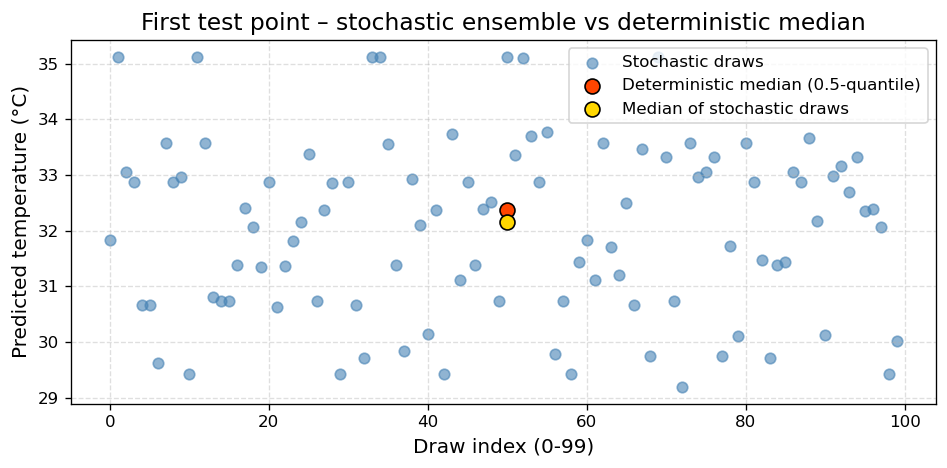

In [27]:
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------------
# 1️⃣  Grab the data for the **first** test point (already printed above)
# ------------------------------------------------------------------
# 100 stochastic draws for the first test sample
stoch_first = stochastic_ensemble[100]          # shape (100,)

# Deterministic median (0.5‑quantile) for the same sample
det_median = median_predictions[100]           # scalar

# Median of the stochastic draws (you also printed)
stoch_median = np.median(stoch_first)       # scalar

# ------------------------------------------------------------------
# 2️⃣  Plot – x‑axis = quantile index (0 … 99)
# ------------------------------------------------------------------
plt.figure(figsize=(8, 4), dpi=120)

# All stochastic draws as semi‑transparent dots
plt.scatter(
    np.arange(len(stoch_first)),
    stoch_first,
    color='steelblue',
    alpha=0.6,
    s=40,
    label='Stochastic draws'
)

# Deterministic median (single red dot)
plt.scatter(
    [len(stoch_first)//2],          # place it roughly in the centre for visibility
    [det_median],
    color='orangered',
    edgecolor='black',
    s=80,
    zorder=5,
    label='Deterministic median (0.5‑quantile)'
)

# Stochastic median (gold dot)
plt.scatter(
    [len(stoch_first)//2],
    [stoch_median],
    color='gold',
    edgecolor='black',
    s=80,
    zorder=5,
    label='Median of stochastic draws'
)

# ------------------------------------------------------------------
# 3️⃣  Styling
# ------------------------------------------------------------------
plt.title('First test point – stochastic ensemble vs deterministic median', fontsize=14)
plt.xlabel('Draw index (0‑99)', fontsize=12)
plt.ylabel('Predicted temperature (°C)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(frameon=True, loc='upper right')
plt.tight_layout()
plt.show()


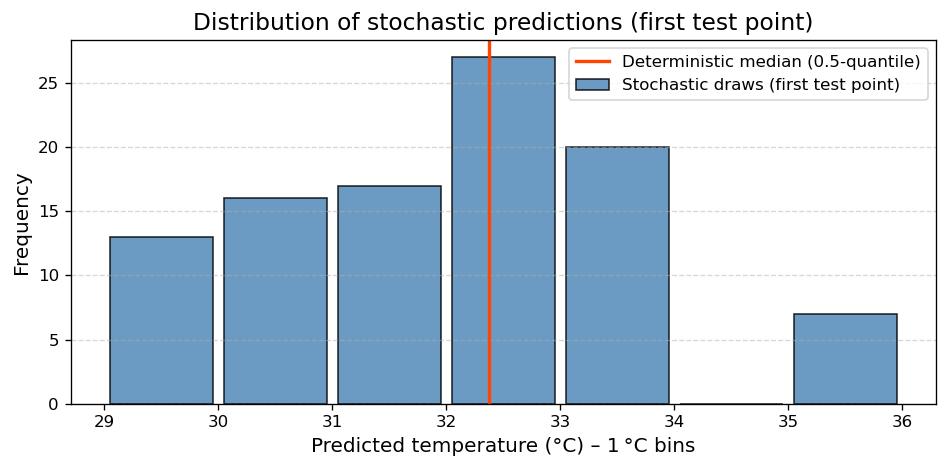

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------
# 1️⃣  Data to histogram – first test point only
# -------------------------------------------------
stoch_first = stochastic_ensemble[100]   # shape (100,)

# -------------------------------------------------
# 2️⃣  Compute histogram with 1 °C bin width
# -------------------------------------------------
# Determine the range that covers the data (rounded to whole degrees)
min_val = np.floor(stoch_first.min())
max_val = np.ceil(stoch_first.max())
# Bin edges: every integer degree between min and max (inclusive)
bins = np.arange(min_val, max_val + 1, 1)   # step = 1 °C

# `np.histogram` returns counts per bin
counts, bin_edges = np.histogram(stoch_first, bins=bins)

# -------------------------------------------------
# 3️⃣  Plot the distribution (x = bin centre, y = frequency)
# -------------------------------------------------
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

plt.figure(figsize=(8, 4), dpi=120)
plt.bar(
    bin_centers,
    counts,
    width=0.9,               # slightly narrower than the bin width for visual separation
    color='steelblue',
    edgecolor='black',
    alpha=0.8,
    label='Stochastic draws (first test point)'
)

# Optionally overlay the deterministic median as a vertical line
plt.axvline(median_predictions[100], color='orangered', linewidth=2,
            label='Deterministic median (0.5‑quantile)')

plt.title('Distribution of stochastic predictions (first test point)', fontsize=14)
plt.xlabel('Predicted temperature (°C) – 1 °C bins', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(frameon=True, loc='upper right')
plt.tight_layout()
plt.show()
